# Bifurcation Sweeps

:::{tip} Run interactively
Run this notebook interactively in your browser with zero installation:
- **[Open in JupyterLite Lab](/lite/lab/index.html?path=user-guide/sweep/bifurcation.ipynb)**
:::

A {term}`bifurcation` marks a qualitative shift in a model's attractor structure as a {term}`control parameter` crosses a critical threshold (see [Bifurcation analysis](../../explanation/bifurcation-analysis.md) for the dynamical-systems theory). This notebook shows how to map bifurcations numerically in hybrid networks:

1. **1D bifurcation profile** — discard initial {term}`transient` activity and track post-transient min/max envelopes and means across {term}`excitability`.
2. **2D regime diagram (`grid=True`)** — map oscillation amplitude and dominant frequency across a Cartesian product of model excitability and inter-subnetwork coupling.
3. **Bistability and hysteresis (`initial_conditions`)** — reveal coexisting upper and lower attractors by sweeping from distinct initial states.

In [1]:
%matplotlib inline
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import scipy.sparse as sp
import matplotlib.pyplot as plt

from tvb.simulator.hybrid import Subnetwork, IntraProjection, InterProjection, NetworkSet
from tvb.simulator.hybrid.coupling import Linear
from tvb.simulator.models import MontbrioPazoRoxin, SupHopf
from tvb.simulator.integrators import HeunDeterministic
from tvb.simulator.backend.cpp_hybrid import notebook as nb, features as feat

## 1. 1D bifurcation sweep across excitability (`MontbrioPazoRoxin` hybrid network)

We couple two `MontbrioPazoRoxin` subnetworks (`A` $\to$ `B`, 4 nodes each, with intra-connectivity on `A`) and sweep `A.eta` across `[-7.0, -2.0]`. We discard the first half of the time series as burn-in and examine the steady-state response in both the driven subnetwork `A` and downstream subnetwork `B`.

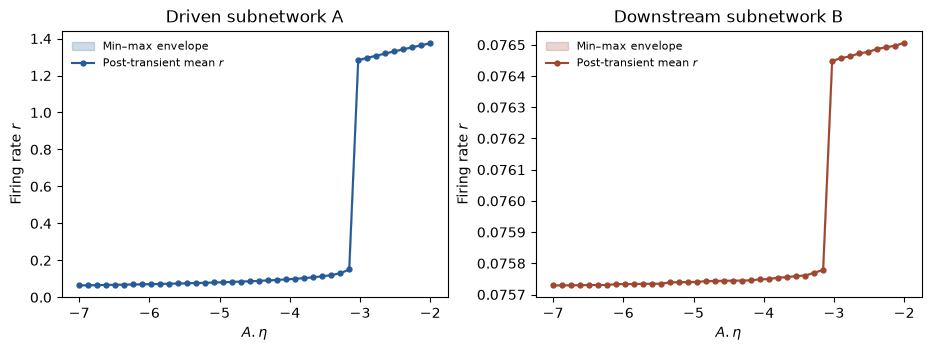

In [2]:
dt = 0.05
c0 = np.array([0], dtype=np.int_)

def build_mpr_pair(J=15.0, Delta=1.0):
    mA = MontbrioPazoRoxin(J=np.array([J]), Delta=np.array([Delta]), eta=np.array([-4.5]))
    mA.configure()
    mB = MontbrioPazoRoxin(J=np.array([J]), Delta=np.array([Delta]), eta=np.array([-5.5]))
    mB.configure()
    snA = Subnetwork(name="A", model=mA, scheme=HeunDeterministic(dt=dt), nnodes=4)
    w_intra = sp.csr_matrix(np.full((4, 4), 0.02, dtype=np.float32) * (1 - np.eye(4, dtype=np.float32)))
    snA.projections = [
        IntraProjection(
            source_cvar=c0, target_cvar=c0, weights=w_intra,
            lengths=sp.csr_matrix((4, 4), dtype=np.float32),
            cv=1.0, dt=dt, scale=0.2, cfun=Linear(),
        )
    ]
    snA.configure()
    snB = Subnetwork(name="B", model=mB, scheme=HeunDeterministic(dt=dt), nnodes=4).configure()
    w_ab = sp.csr_matrix(np.full((4, 4), 0.05, dtype=np.float32))
    proj = InterProjection(
        source=snA, target=snB, source_cvar=c0, target_cvar=c0,
        weights=w_ab, lengths=sp.csr_matrix((4, 4), dtype=np.float32),
        cv=1.0, dt=dt, scale=0.3, cfun=Linear(),
    )
    return NetworkSet(subnets=[snA, snB], projections=[proj]).configure()

ns_mpr = build_mpr_pair()
etas = np.linspace(-7.0, -2.0, 40, dtype=np.float32)
ic_low = [
    np.array([np.full((4, 1), 0.05), np.full((4, 1), -2.0)]),
    np.array([np.full((4, 1), 0.05), np.full((4, 1), -2.0)]),
]

res_1d = nb.sweep(ns_mpr, nstep=1200, initial_states=ic_low, **{"A.eta": etas})
r_A = res_1d.squeezed("A")[:, 600:, 0, :]  # drop first 600 steps (burn-in)
r_B = res_1d.squeezed("B")[:, 600:, 0, :]
assert np.isfinite(r_A).all() and np.isfinite(r_B).all()

fig, axes = plt.subplots(1, 2, figsize=(9.2, 3.4), layout="constrained")
for ax, data, title, col in [
    (axes[0], r_A, "Driven subnetwork A", "#275b97"),
    (axes[1], r_B, "Downstream subnetwork B", "#9e4830"),
]:
    mean_node = data.mean(axis=(1, 2))
    lo_env = data.min(axis=(1, 2))
    hi_env = data.max(axis=(1, 2))
    ax.fill_between(etas, lo_env, hi_env, color=col, alpha=0.22, label="Min–max envelope")
    ax.plot(etas, mean_node, "o-", ms=3.5, color=col, label="Post-transient mean $r$")
    ax.set(title=title, xlabel="$A.\\eta$", ylabel="Firing rate $r$")
    ax.legend(frameon=False, fontsize=8)
plt.show()

## 2. 2D regime map with `grid=True` (bidirectional `SupHopf` hybrid network)

Passing `grid=True` to `nb.sweep` expands the Cartesian product of keyword parameters in insertion order, with the last parameter varying fastest (`(n_a * n_g, 2)`). We sweep cortical excitability `cortex.a` $\times$ `coupling_scale` in a reciprocally coupled two-frequency `SupHopf` network (`20 Hz` cortex $\leftrightarrow$ `12 Hz` subcortex), extract post-transient oscillation amplitude (`std`) and dominant frequency (`spectrum_stats`) via `features.compute_features`, and reshape back onto the `(n_a, n_g)` grid.

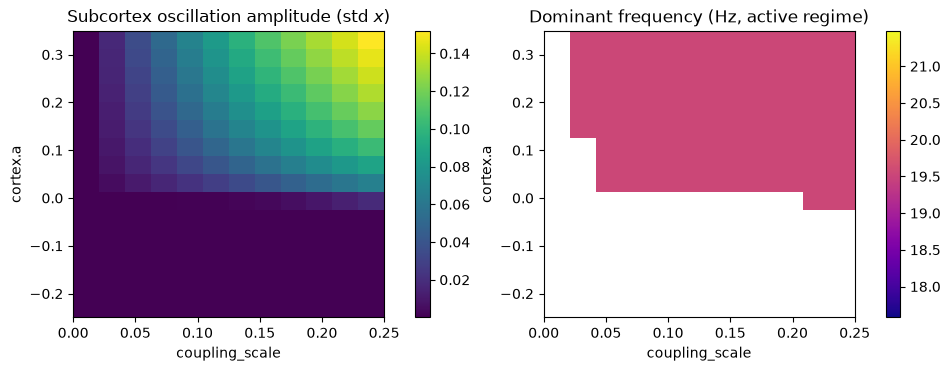

In [3]:
dt_osc = 0.2
m_osc = SupHopf(a=np.array([-0.1]), omega=np.array([2 * np.pi * 0.020]), variables_of_interest=("x", "y"))
m_osc.configure()
m_tgt = SupHopf(a=np.array([-0.05]), omega=np.array([2 * np.pi * 0.012]), variables_of_interest=("x", "y"))
m_tgt.configure()

sn_osc = Subnetwork(name="cortex", model=m_osc, scheme=HeunDeterministic(dt=dt_osc), nnodes=4).configure()
sn_tgt = Subnetwork(name="subcortex", model=m_tgt, scheme=HeunDeterministic(dt=dt_osc), nnodes=4).configure()
w_4 = sp.csr_matrix(np.eye(4, dtype=np.float32))
l_4 = sp.csr_matrix((4, 4), dtype=np.float32)
proj_cs = InterProjection(source=sn_osc, target=sn_tgt, source_cvar=c0, target_cvar=c0, weights=w_4, lengths=l_4, cv=1.0, dt=dt_osc, scale=0.2, cfun=Linear())
proj_sc = InterProjection(source=sn_tgt, target=sn_osc, source_cvar=c0, target_cvar=c0, weights=w_4, lengths=l_4, cv=1.0, dt=dt_osc, scale=0.08, cfun=Linear())
ns_2d = NetworkSet(subnets=[sn_osc, sn_tgt], projections=[proj_cs, proj_sc]).configure()

a_grid = np.linspace(-0.25, 0.35, 16, dtype=np.float32)
g_grid = np.linspace(0.0, 0.25, 12, dtype=np.float32)
ic_2d = [np.full((2, 4, 1), 0.1), np.full((2, 4, 1), 0.1)]

res_2d = nb.sweep(
    ns_2d,
    nstep=4000,
    monitor="tavg",
    monitor_period=5,
    chunk_size=5,
    grid=True,
    initial_states=ic_2d,
    **{"cortex.a": a_grid},
    coupling_scale=g_grid,
)
# Sample interval: 5 * 0.2 ms = 1.0 ms -> fs = 1000 Hz; 800 samples total, drop first 300
sub_x = res_2d.squeezed("subcortex")[:, 300:, 0, :]
sub_dm = sub_x - sub_x.mean(axis=1, keepdims=True)
spec_2d = dict(feat.compute_features(np.moveaxis(sub_dm, 1, 0), ["std", "spectrum_stats"], fs=1000.0))

amp_map = spec_2d["std"].mean(axis=1).reshape(len(a_grid), len(g_grid))
fpeak_map = spec_2d["spectrum_stats"][1].mean(axis=1).reshape(len(a_grid), len(g_grid))
fpeak_masked = np.where(amp_map > 1e-2, fpeak_map, np.nan)
assert np.nanmax(amp_map) > 0.05

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9.4, 3.6), layout="constrained")
im1 = ax1.imshow(amp_map, origin="lower", aspect="auto", extent=[g_grid[0], g_grid[-1], a_grid[0], a_grid[-1]], cmap="viridis")
ax1.set(title="Subcortex oscillation amplitude (std $x$)", xlabel="coupling_scale", ylabel="cortex.a")
fig.colorbar(im1, ax=ax1)

im2 = ax2.imshow(fpeak_masked, origin="lower", aspect="auto", extent=[g_grid[0], g_grid[-1], a_grid[0], a_grid[-1]], cmap="plasma")
ax2.set(title="Dominant frequency (Hz, active regime)", xlabel="coupling_scale", ylabel="cortex.a")
fig.colorbar(im2, ax=ax2)
plt.show()

## 3. Detecting bistability and hysteresis via `initial_conditions`

When a model exhibits {term}`bistability` (`MontbrioPazoRoxin` with $J=15, \Delta=1$), a single-initial-condition sweep only traces one branch. Running the **identical** `nb.sweep` from low-activity vs. high-activity initial conditions reveals the coexisting up- and down-state branches and the hysteresis interval between the saddle-node bifurcations.

Maximum up/down branch separation: 1.128


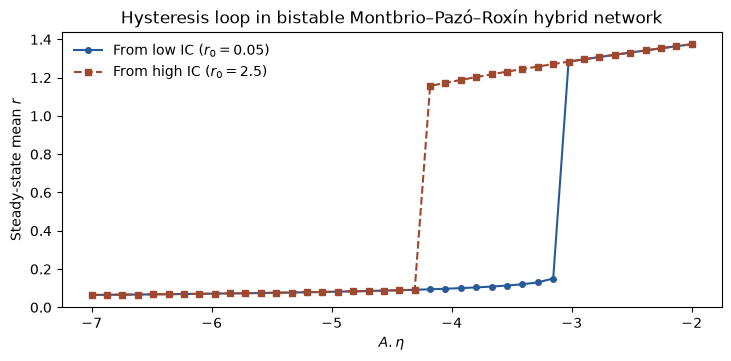

In [4]:
ic_high = [
    np.array([np.full((4, 1), 2.5), np.full((4, 1), 0.0)]),
    np.array([np.full((4, 1), 2.5), np.full((4, 1), 0.0)]),
]

res_lo = nb.sweep(ns_mpr, nstep=1200, initial_states=ic_low, **{"A.eta": etas})
res_hi = nb.sweep(ns_mpr, nstep=1200, initial_states=ic_high, **{"A.eta": etas})

branch_lo = res_lo.squeezed("A")[:, 600:, 0, :].mean(axis=(1, 2))
branch_hi = res_hi.squeezed("A")[:, 600:, 0, :].mean(axis=(1, 2))
hyst_gap = np.max(np.abs(branch_hi - branch_lo))
assert hyst_gap > 0.5, f"Expected bistable separation, got {hyst_gap}"
print(f"Maximum up/down branch separation: {hyst_gap:.3f}")

fig, ax = plt.subplots(figsize=(7.2, 3.5), layout="constrained")
ax.plot(etas, branch_lo, "o-", color="#275b97", ms=4, label="From low IC ($r_0=0.05$)")
ax.plot(etas, branch_hi, "s--", color="#9e4830", ms=4, label="From high IC ($r_0=2.5$)")
ax.set(title="Hysteresis loop in bistable Montbrio–Pazó–Roxín hybrid network", xlabel="$A.\\eta$", ylabel="Steady-state mean $r$")
ax.legend(frameon=False)
plt.show()

## Next steps

- [Monte Carlo and Quasi-Monte Carlo Sweeps](mc-sampling.ipynb) — explore $D \ge 3$ parameter spaces without the $N^D$ grid explosion.
- [Hybrid Sweep Workflows and Performance](backends.ipynb) — inspect PSD and Balloon–Windkessel FC transitions across excitability.